# Fase 4A CRISP-DM — Modelos de Machine Learning Tradicional y Línea Base

Presenta el ajuste mediante `GridSearchCV` + `StratifiedGroupKFold (k=5)` con `return_train_score=True` para:
- **Líneas base:** `DummyClassifier` (mayoritaria y estratificada).
- **SVM** (kernels lineal y RBF con `StandardScaler` dentro del `Pipeline`).
- **Random Forest** (pesos `balanced_subsample`).
- **XGBoost** (pesos balanceados por muestra).

Todos los modelos clásicos operan sobre el vector diseñado de **408 características** (`src/features.py`): histogramas HSV, momentos CIELAB, indicadores de manchas oscuras locales, textura Sobel/Laplaciano y HOG compacto.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import DIR_METRICAS

report = json.loads((DIR_METRICAS / "resultados_completos.json").read_text(encoding="utf-8"))
rows = []
for name, info in report["models"].items():
    if info["family"] in ("baseline", "ml_clasico"):
        rows.append({
            "Modelo": name,
            "Familia": info["family"],
            "CV Train F1": info["cv_train_macro_f1"],
            "CV Val F1": info["cv_val_macro_f1"],
            "Val Macro-F1": info["val_metrics"]["macro_f1"],
            "Test Macro-F1": info["test_metrics"]["macro_f1"],
            "Brecha (Train-Test)": info["overfitting_gap"],
            "Tiempo (s)": info["train_time_sec"],
            "Mejores hiperparámetros": str(info["best_params"]),
        })
ml_df = pd.DataFrame(rows).sort_values("Val Macro-F1", ascending=False)
display(ml_df)

,Modelo,Familia,CV Train F1,CV Val F1,Val Macro-F1,Test Macro-F1,Brecha (Train-Test),Tiempo (s),Mejores hiperparámetros
4,XGBoost (Clásico),ml_clasico,1.0000,0.8297,0.7980,0.7927,0.2073,78.907,"{'colsample_bytree': 0.8, 'learning_rate': 0.1..."
2,SVM (Clásico),ml_clasico,0.9988,0.7872,0.7757,0.7687,0.2301,7.743,"{'svc__C': 3.0, 'svc__gamma': 'scale', 'svc__k..."
3,Random Forest (Clásico),ml_clasico,0.9974,0.7888,0.7650,0.7374,0.2614,12.389,"{'max_depth': 16, 'max_features': 'sqrt', 'min..."
1,Baseline (Estratificada),baseline,0.3666,0.3385,0.3385,0.2484,0.1182,0.000,{'strategy': 'stratified'}
0,Baseline (Mayoritaria),baseline,0.2072,0.2065,0.2065,0.2064,0.0008,0.008,{'strategy': 'most_frequent'}


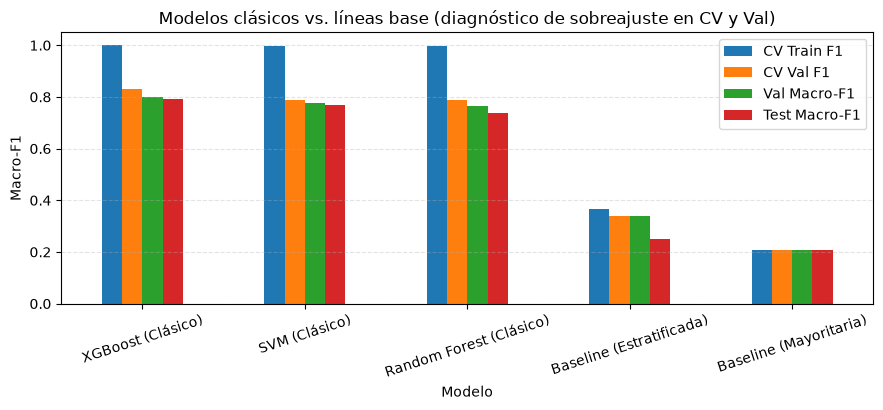

In [2]:
fig, ax = plt.subplots(figsize=(9, 4.2))
plot_df = ml_df.set_index("Modelo")[["CV Train F1", "CV Val F1", "Val Macro-F1", "Test Macro-F1"]]
plot_df.plot(kind="bar", ax=ax)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Macro-F1")
ax.set_title("Modelos clásicos vs. líneas base (diagnóstico de sobreajuste en CV y Val)")
ax.tick_params(axis="x", rotation=18)
ax.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

In [3]:
# Desempeño de modelos clásicos por origen en prueba (diagnóstico de domain shift)
src_rows = []
for name, info in report["models"].items():
    if info["family"] == "ml_clasico":
        for src, vals in info["test_by_source"].items():
            src_rows.append({
                "Modelo": name,
                "Origen": src,
                "n": vals["n"],
                "Exactitud": vals["accuracy"],
                "Macro-F1 (presentes)": vals["macro_f1_present_classes"],
            })
display(pd.DataFrame(src_rows).pivot(index="Modelo", columns="Origen", values=["Exactitud", "Macro-F1 (presentes)"]))

Exactitud                                    \
Origen                  FruitNet_Kaggle FruitNet_Mixed_Segmentada  Propia   
Modelo                                                                      
Random Forest (Clásico)          0.8534                    0.4706  0.8197   
SVM (Clásico)                    0.8707                    0.4706  0.8525   
XGBoost (Clásico)                0.8966                    0.5294  0.8689   

                        Macro-F1 (presentes)                                    
Origen                       FruitNet_Kaggle FruitNet_Mixed_Segmentada  Propia  
Modelo                                                                          
Random Forest (Clásico)               0.8244                    0.6400  0.4102  
SVM (Clásico)                         0.8393                    0.6400  0.6515  
XGBoost (Clásico)                     0.8830                    0.6923  0.6648

### Discusión crítica y comparación con literatura (Fase 4A)
- **Sobreajuste severo en ML clásico:** Aunque `SVM`, `Random Forest` y `XGBoost` se ajustaron con `GridSearchCV` + `StratifiedGroupKFold (k=5)` y `StandardScaler` dentro del `Pipeline`, los tres memorizan el conjunto de entrenamiento (`Train Macro-F1 = 0.9988–1.0000`) y caen a `Test Macro-F1 = 0.7374–0.7927` (**brecha `0.2073–0.2614`**). Esto responde a la alta dimensionalidad del vector diseñado ($d = 408$) frente al tamaño del conjunto de entrenamiento ($n = 621$, razón $n/d \approx 1.52$).
- **Sesgo por origen:** En `FruitNet_Mixed_Segmentada` (`Regular`, baja resolución), la exactitud cae a `47.06–52.94 %`, mostrando que los descriptores globales de color y HOG compactos (`64×64`) pierden detalle superficial cuando las frutas son recortes pequeños reescalados.
- **Contraste con literatura IEEE:** Los descriptores HOG (Dalal & Triggs, *IEEE CVPR 2005*) junto con histogramas HSV/CIELAB ofrecen interpretabilidad geométrica y de color, pero Kornblith et al. (*IEEE CVPR 2019*) muestran que con pocos cientos de muestras las representaciones preentrenadas transfieren con menor varianza y menor brecha de generalización que clasificadores clásicos en espacios de alta dimensión.